In [ ]:
# ==============================================================================
# Laboratory Assignment: Image Processing with Python (OpenCV, PIL, scikit-image)
# Setup and Dependency Imports
# ==============================================================================

# OpenCV (cv2): Core computer vision library used for image loading, color conversion, transformation, and processing
import cv2

import numpy as np

# Matplotlib.pyplot: Visualization library used for plotting and displaying images inline
import matplotlib.pyplot as plt

# PIL (Pillow): Python Imaging Library used for image file reading, format handling, and saving
from PIL import Image

# scikit-image metrics: Provides quantitative image comparison metrics such as Mean Squared Error (MSE)
from skimage.metrics import mean_squared_error

# 1
**Objective:** Load an image using OpenCV and render it using Matplotlib with proper color space conversion (BGR to RGB).

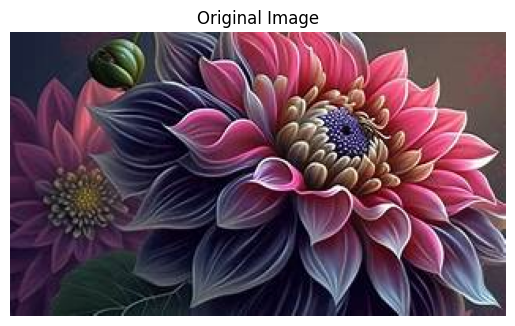

In [ ]:
# Step 1: Read the input image from disk using OpenCV
# cv2.imread loads the image as a NumPy BGR (Blue-Green-Red) array by default
img = cv2.imread('OIP (1).jpg')

# Step 2: Convert color space from BGR to RGB
# Matplotlib interprets color channels in RGB order. Without conversion, colors will appear swapped/tinted.
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

# Step 3: Set plot title and remove axis tick marks and borders for clean presentation
plt.title('Original Image')
plt.axis('off')

# Step 4: Render the figure inline
plt.show()

# 2
**Objective:** Inspect image properties including dimensions (height, width), color channels, and data type.

In [ ]:
# Step 1: Load the target image using OpenCV (returns a NumPy array of shape: height x width x channels)
img2 = cv2.imread('OIP (2).jpg')

# Step 2: Extract spatial dimensions (height and width) from the shape tuple: shape[:2] -> (height, width)
height, width = img2.shape[:2]

# Step 3: Extract the number of color channels (index 2 corresponds to color channels, e.g., 3 for BGR)
channels = img2.shape[2]

# Step 4: Display the image resolution and channel depth
print(f"Dimensions: [{height}, {width}, {channels}]")

# Step 5: Check and display the underlying data type of pixel values (typically uint8: 8-bit unsigned integers, 0 to 255)
print("Data type:", img2.dtype)

Dimensions: [180, 320, 3]
Data type: uint8


# 3
**Objective:** Convert a color image to Grayscale and display a side-by-side comparison with the original image.

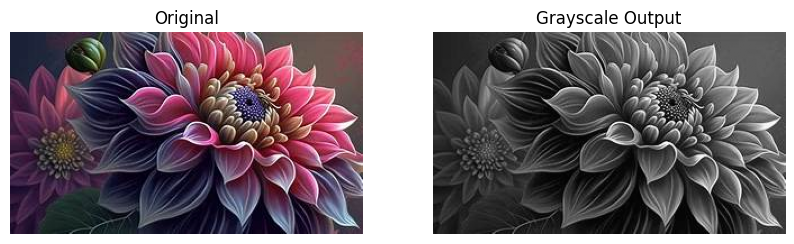

In [ ]:
# Step 1: Read the original color image
img3 = cv2.imread('OIP (1).jpg')

# Step 2: Convert the 3-channel BGR image into a 1-channel Grayscale image
# OpenCV uses the weighted luminance formula: Y = 0.299*R + 0.587*G + 0.114*B
gray = cv2.cvtColor(img3, cv2.COLOR_BGR2GRAY)

# Step 3: Create a figure for side-by-side visualization (1 row, 2 columns) with 10x4 inch size
plt.figure(figsize=(10,4))

# Subplot 1 (Left): Display the original color image (converted from BGR to RGB for correct matplotlib colors)
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

# Subplot 2 (Right): Display the grayscale image using gray colormap (cmap='gray')
plt.subplot(1,2,2)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Output")
plt.axis("off")

# Step 4: Render side-by-side comparison
plt.show()

# 4
**Objective:** Save and write images using Pillow (PIL) and OpenCV, and display the saved image.

In [ ]:
# Method 1: Using Pillow (PIL)
# Open the source JPEG image using Pillow's Image module
img_pil = Image.open('OIP (3).jpg')

# Save/convert the opened image as a PNG file using Pillow
img_pil.save('image_pilll.png')

# Method 2: Using OpenCV
# Load the image using OpenCV (loads as BGR NumPy array)
image = cv2.imread('OIP (3).jpg')

# Save/write the NumPy array to disk in PNG format using OpenCV's imwrite function
cv2.imwrite('image_pilll.png',image)

True

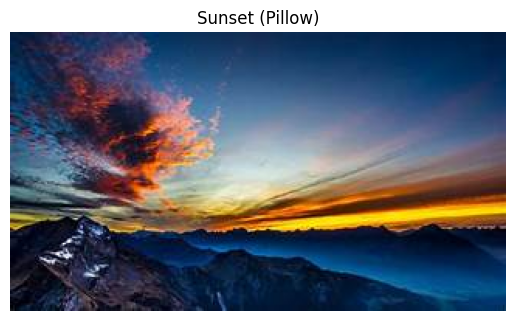

In [ ]:
# Step 1: Re-open the saved PNG image using Pillow
img_pil = Image.open('image_pilll.png')

# Step 2: Display the image directly using Matplotlib (Pillow images are natively RGB)
plt.imshow(img_pil)

# Step 3: Add title and hide axis coordinates
plt.title('Sunset (Pillow)')
plt.axis('off')

# Step 4: Display the image window
plt.show()

# 5
**Objective:** Resize an image to 50% of its original resolution using OpenCV with area interpolation.

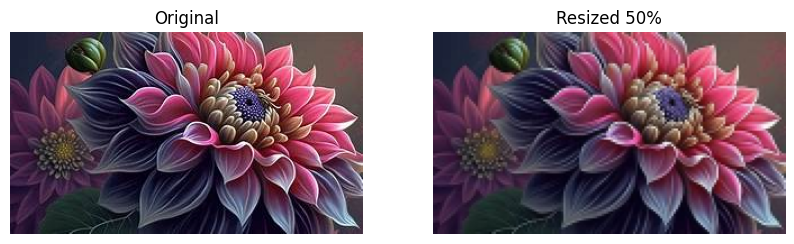

In [ ]:
# Step 1: Read the original image
img5 = cv2.imread('OIP (1).jpg')

# Step 2: Extract current spatial dimensions: height (h) and width (w)
h, w = img5.shape[:2]

# Step 3: Resize image to half its original dimensions (50% scale)
# Note: cv2.resize expects destination size as (width, height), opposite of numpy shape (height, width)
# cv2.INTER_AREA is the recommended resampling filter for image decimation/shrinking to avoid moire artifacts
resized = cv2.resize(img5, (w//2, h//2),interpolation=cv2.INTER_AREA)

# Step 4: Create a side-by-side plot comparing original vs resized image
plt.figure(figsize=(10,4))

# Subplot 1: Display the original full-resolution image
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img5, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

# Subplot 2: Display the 50% scaled-down resized image
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized 50%")
plt.axis("off")

# Render comparison plot
plt.show()

# 6
**Objective:** Crop a specific Region of Interest (ROI) around the center of the image using NumPy slicing.

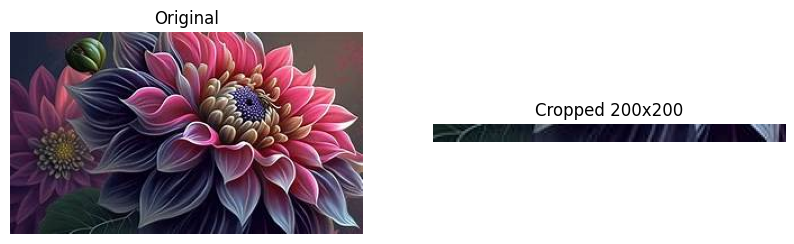

In [ ]:
# Step 1: Load the source image
img6 = cv2.imread("OIP (1).jpg")

# Step 2: Extract height (h) and width (w) to compute center coordinates
h, w = img6.shape[:2]
cy, cx = h//2, w//2

# Step 3: Perform rectangular crop around the center using NumPy array slicing
# Slices 100 pixels in each direction: vertical [cy-100:cy+100] and horizontal [cx-100:cx+100]
# Resulting crop size: 200 x 200 pixels
crop = img6[cy-100:cy+100, cx-100:cx+100]

# Step 4: Visualize the original image alongside the cropped center region
plt.figure(figsize=(10,4))

# Subplot 1: Full original image
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img6, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

# Subplot 2: 200x200 cropped region
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.title("Cropped 200x200")
plt.axis("off")

# Render comparison plot
plt.show()

# 7
**Objective:** Rotate an image by 90 degrees around its center using an affine transformation matrix.

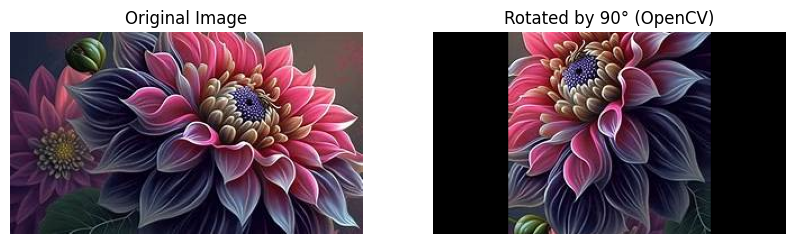

In [ ]:
# Import required modules (ensures cell self-containment)
import cv2
import matplotlib.pyplot as plt

# Step 1: Read the source image
img_cv1 = cv2.imread('OIP (1).jpg')

# Step 2: Determine center point of rotation (width/2, height/2)
(h, w) = img_cv1.shape[:2]
center = (w//2, h//2)

# Step 3: Compute the 2D affine rotation matrix
# Parameters: center point, rotation angle in degrees (counter-clockwise: 90), and isotropic scale factor (1.0)
M = cv2.getRotationMatrix2D(center, 90, 1.0)

# Step 4: Apply affine transformation using the computed matrix M
# Destination size is maintained as (w, h)
rotated = cv2.warpAffine(img_cv1, M, (w, h))

# Step 5: Plot original and rotated images side by side
plt.figure(figsize=(10,4))

# Subplot 1: Display original orientation
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_cv1, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Subplot 2: Display 90-degree rotated image
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
plt.title("Rotated by 90° (OpenCV)")
plt.axis("off")

# Render comparison plot
plt.show()

# 8
**Objective:** Flip an image horizontally (left-to-right mirror reflection) using `cv2.flip`.

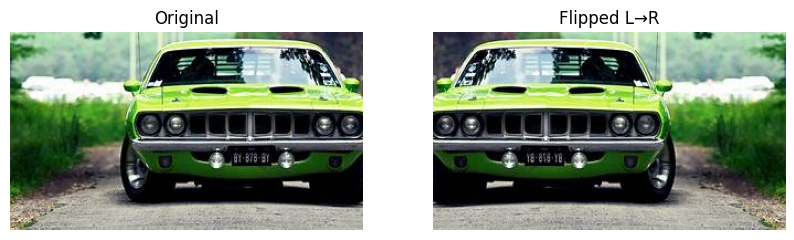

In [ ]:
# Step 1: Read the input image
img8 = cv2.imread("OIP (4).jpg")

# Step 2: Flip the image horizontally (left-to-right reflection)
# flipCode options:
#    0: Vertical flip (around x-axis)
#    1: Horizontal flip (around y-axis, Left -> Right)
#   -1: Simultaneous horizontal and vertical flip (around both axes)
flip = cv2.flip(img8, 1)

# Step 3: Display original and horizontally flipped images side by side
plt.figure(figsize=(10,4))

# Subplot 1: Original image
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img8, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

# Subplot 2: Horizontally flipped image
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(flip, cv2.COLOR_BGR2RGB))
plt.title("Flipped L→R")
plt.axis("off")

# Render comparison plot
plt.show()

# 9
**Objective:** Convert image to HSV color space and decompose into Hue, Saturation, and Value channels.

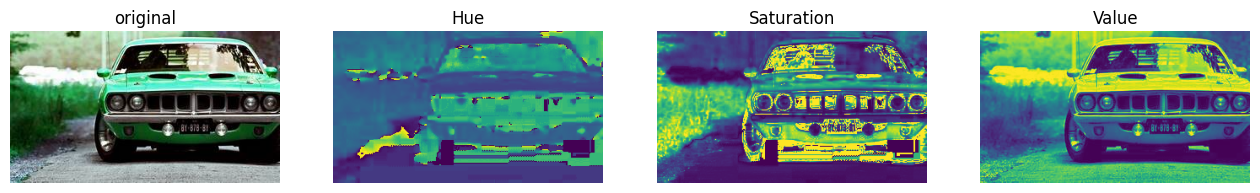

In [ ]:
# Step 1: Load image in BGR format
img9 = cv2.imread('OIP (4).jpg')

# Step 2: Convert color space from BGR to HSV (Hue, Saturation, Value)
# Hue represents dominant color tint/wavelength (range: [0, 179] in OpenCV)
# Saturation represents purity or vibrancy of the color (range: [0, 255])
# Value represents perceived brightness/light intensity (range: [0, 255])
hsv = cv2.cvtColor(img9, cv2.COLOR_BGR2HSV)

# Step 3: Split the 3-channel HSV image into individual 2D channel arrays (H, S, V)
h, s, v = cv2.split(hsv)

# Step 4: Visualize original image alongside Hue, Saturation, and Value channels
plt.figure(figsize=(16, 4))

# Panel 1: Original input image
plt.subplot(1, 4, 1)
plt.imshow(img9)
plt.title('original')
plt.axis('off')

# Panel 2: Hue (H) channel map (color tone)
plt.subplot(1, 4, 2)
plt.imshow(h)
plt.title('Hue')
plt.axis('off')

# Panel 3: Saturation (S) channel map (color purity/intensity)
plt.subplot(1, 4, 3)
plt.imshow(s)
plt.title('Saturation')
plt.axis('off')

# Panel 4: Value (V) channel map (brightness distribution)
plt.subplot(1, 4, 4)
plt.imshow(v)
plt.title('Value')
plt.axis('off')

# Render 4-panel comparison
plt.show()

# 10
**Objective:** Compute Mean Squared Error (MSE) between images to quantify difference/similarity.

In [ ]:
# Step 1: Load two images directly in grayscale mode using cv2.IMREAD_GRAYSCALE
img1 = cv2.imread('OIP (3).jpg', cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread('OIP (2).jpg', cv2.IMREAD_GRAYSCALE)

# Step 2: Compute Mean Squared Error (MSE) between the two grayscale images
# MSE measures average squared difference between corresponding pixels: MSE = (1/N) * sum((I1 - I2)^2)
# Lower values indicate higher similarity (0 = identical images)
mse_value = mean_squared_error(img1, img2)

# Step 3: Print the calculated MSE rounded to 2 decimal places
print(f"Mean Squared Error (MSE): {mse_value:.2f}")

Mean Squared Error (MSE): 6899.44


MSE = 6899.43671875


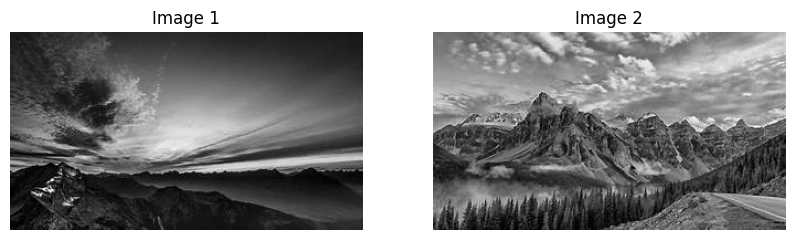

In [ ]:
# Alternative method: Load images in grayscale using flag 0 (equivalent to cv2.IMREAD_GRAYSCALE)
img10_a = cv2.imread("OIP (3).jpg", 0)
img10_b = cv2.imread("OIP (2).jpg", 0)

# Compute Mean Squared Error (MSE) between both images
mse_value = mean_squared_error(img10_a, img10_b)
print("MSE =", mse_value)

# Visual comparison: Plot both grayscale images side by side
plt.figure(figsize=(10,4))

# Display Image 1
plt.subplot(1,2,1)
plt.imshow(img10_a, cmap='gray')
plt.title("Image 1")
plt.axis("off")

# Display Image 2
plt.subplot(1,2,2)
plt.imshow(img10_b, cmap='gray')
plt.title("Image 2")
plt.axis("off")

# Render comparison plot
plt.show()